In [1]:
import math
from scipy.integrate import odeint
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import sys
from mpl_toolkits.mplot3d import Axes3D
from scipy.integrate import solve_ivp 
from numpy import linalg as LA
import importlib
import import_ipynb
import helper_function
import burgers_helper
from helper_function import *
from burgers_helper import *

In [2]:
# Reload all files containing helper functions
importlib.reload(helper_function)
importlib.reload(burgers_helper)

ModuleSpec(name='helper_function', loader=<import_ipynb.NotebookLoader object at 0x10b3fa7b0>, origin='helper_function.ipynb')

In [12]:
# Define time and spatial bound, grid points
# Spatial domain
N = 100
x = np.linspace(0, 2*np.pi, N, endpoint=False)
delta_x = x[1] - x[0]

# Time domain
T = 0.2
t = np.linspace(0, T, N)
delta_t = t[1] - t[0]

In [13]:
#Solve M = 0 system normally
M0 = 0
u_init_M0 = getinitcond(x, M0, ic_type='cond_1') 
u_init_flat_M0 = u_init_M0.flatten()
M0_result = odeint(GeneralBurgRHS, 
                   u_init_flat_M0, 
                   t, 
                   args = (delta_x,M0,N))

In [14]:
# Solve M = 1 system
M1 = 1
u_init_M1 = getinitcond(x, M1, ic_type='cond_1') 
u_init_flat_M1 = u_init_M1.flatten()

M1_result = odeint(
    GeneralBurgHierachy,
    u_init_flat_M1,
    t,
    args=(delta_x, M1, N)
)

In [15]:
# Initialize M=2 system
M2 = 2

u_init_M2 = getinitcond(x, M2, ic_type="cond_1")
u_init_flat_M2 = u_init_M2.flatten()

for i in range(len(t)-1):
    u0_from_M1 = M1_result[i, 0:N]      
    u1_from_M1 = M1_result[i, N:2*N]   
    
    u_from_M1 = (u0_from_M1, u1_from_M1)
    
    # Solve
    M2_result = odeint(GeneralBurgHierachy, u_init_flat_M2, t, 
                 args=(delta_x, M2, N, u_from_M1))
print(M2_result)

[[ 0.          0.          0.         ...  0.          0.
   0.        ]
 [ 0.         -0.01289603 -0.02555459 ...  0.00039885  0.00027085
   0.00013653]
 [ 0.         -0.01289603 -0.02555459 ...  0.00079802  0.00054192
   0.00027318]
 ...
 [ 0.         -0.01289603 -0.02555459 ...  0.04230143  0.02889667
   0.01460383]
 [ 0.         -0.01289603 -0.02555459 ...  0.04280262  0.02924256
   0.01477942]
 [ 0.         -0.01289603 -0.02555459 ...  0.04330582  0.02958996
   0.0149558 ]]


In [16]:
result_M2_normal = odeint(GeneralBurgRHS, u_init_flat_M2, t, args = (delta_x,M2,N))
print(result_M2_normal)

[[ 0.          0.          0.         ...  0.          0.
   0.        ]
 [ 0.         -0.00012652 -0.00025104 ...  0.00037161  0.00025104
   0.00012627]
 [ 0.         -0.00025304 -0.0005021  ...  0.00074324  0.00050211
   0.00025255]
 ...
 [ 0.         -0.0136731  -0.02701026 ...  0.04168589  0.02845287
   0.01437457]
 [ 0.         -0.01384738 -0.02735118 ...  0.04224785  0.02884461
   0.01457428]
 [ 0.         -0.01402288 -0.02769434 ...  0.0428145   0.02923996
   0.01477591]]


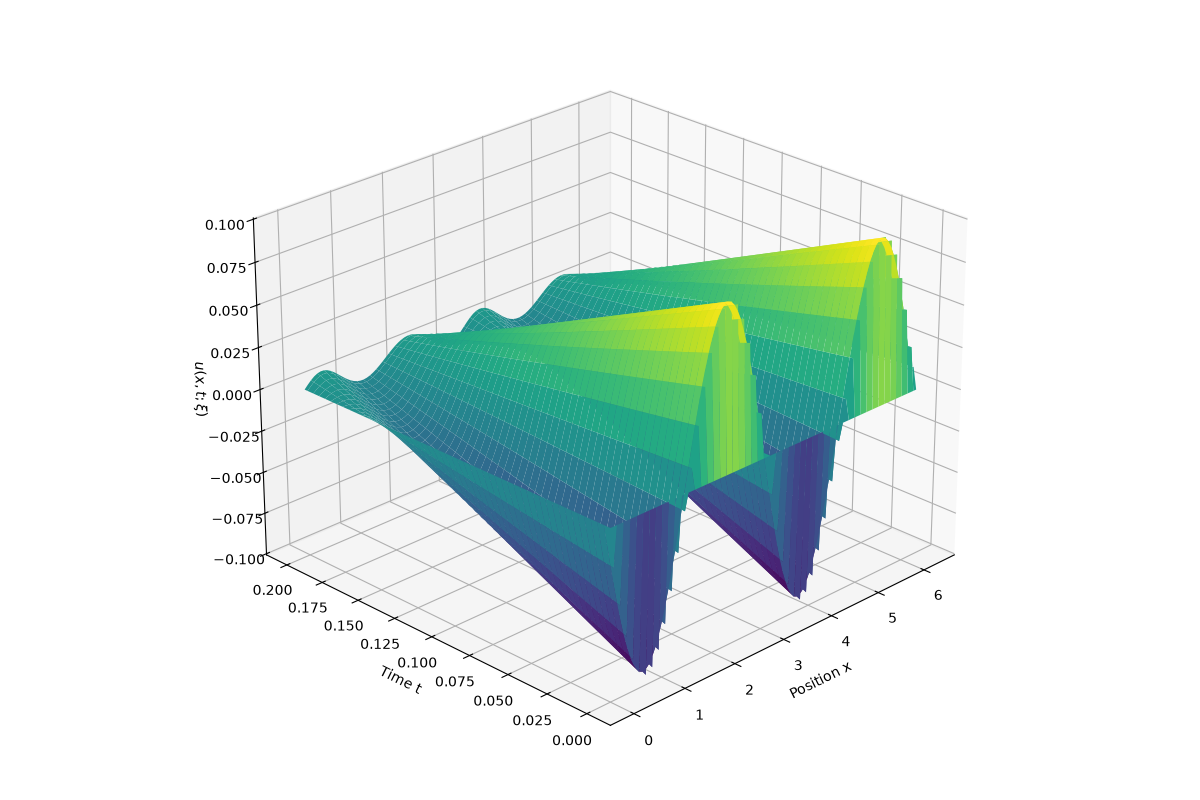

In [37]:
%matplotlib widget
u0atallt_ = M2_result[:, 0:N]
u1atallt_ = M2_result[:, N:2*N]
u2atallt_ = M2_result[:, 2*N:3*N]
x_axis = x
y_axis = t

# Define variables
xi = 0
# Define Hermite polynomials
H0 = 1
H1 = xi
H2 = xi**2 - 1
Z = H0*u0atallt_ + H1*u1atallt_ + H2*u2atallt_

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    edgecolor="none",
    linewidth=0,
    antialiased=True,
    shade=True
)

ax.set_xlabel("Position x")
ax.set_ylabel("Time t")
ax.set_zlabel(r"$u(x,t;\xi)$")
ax.view_init(elev=25, azim=-135)

plt.tight_layout()
plt.show()

/var/folders/j9/4h2kx86j2dv9xn8qn8khd9140000gn/T/ipykernel_29177/2343010625.py:23: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


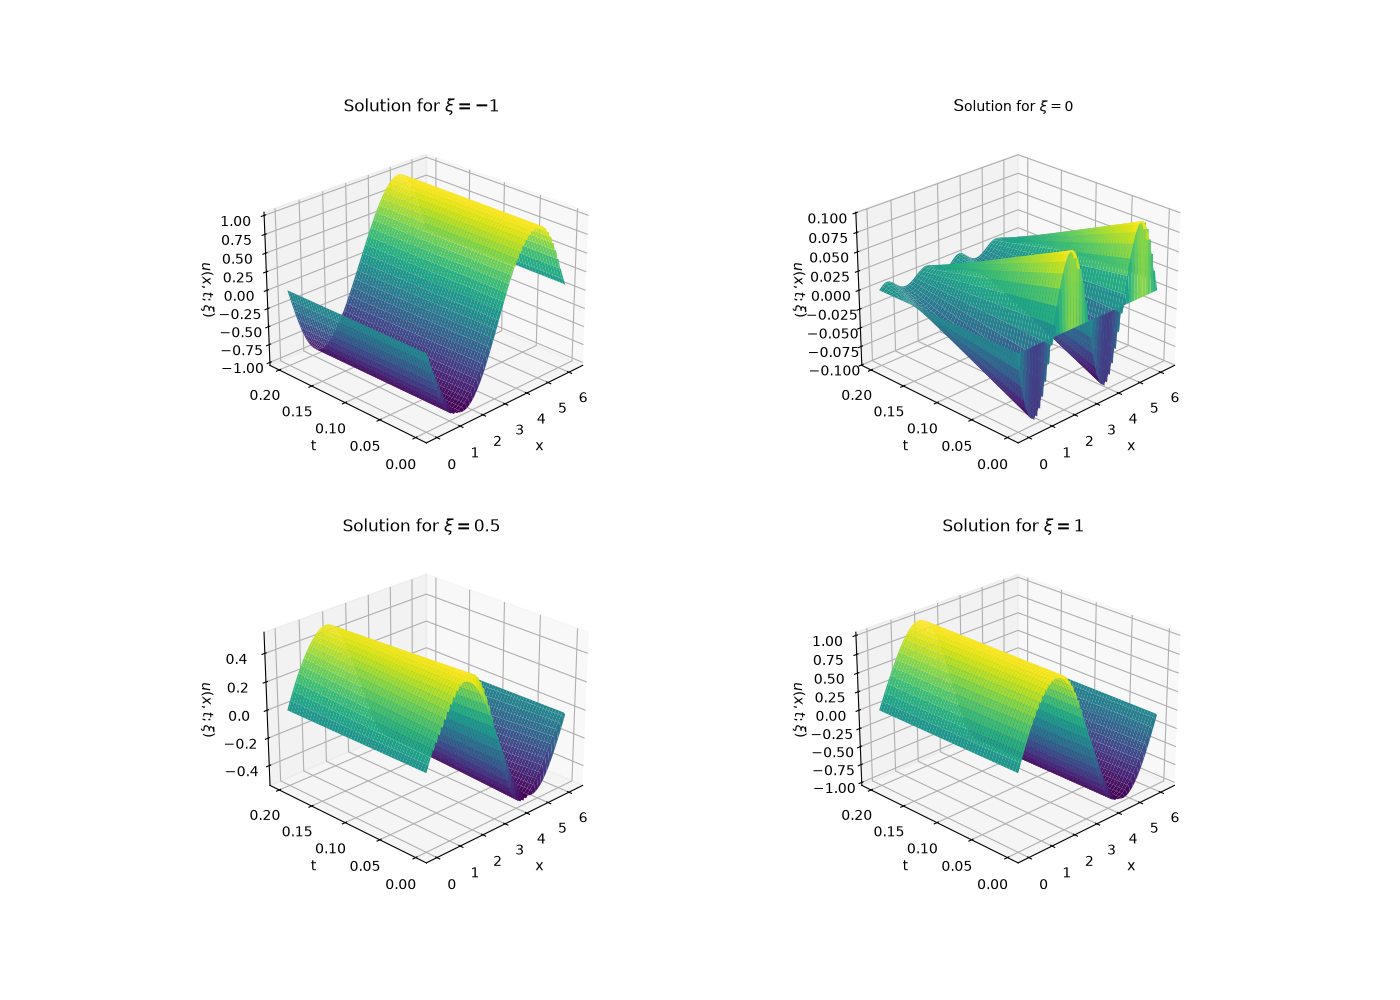

In [40]:
u0 = M2_result[:, :N]
u1 = M2_result[:, N:2*N]
u2 = M2_result[:, 2*N:3*N]

X, Y = np.meshgrid(x, t)

xi_values = [-1, 0, 0.5, 1]

fig = plt.figure(figsize=(14, 10))

for i, xi in enumerate(xi_values):
    Z = u0 + xi*u1 + (xi**2 - 1)*u2

    ax = fig.add_subplot(2, 2, i + 1, projection="3d")
    ax.plot_surface(X, Y, Z, cmap="viridis", edgecolor="none")

    ax.set_xlabel("x")
    ax.set_ylabel("t")
    ax.set_zlabel(r"$u(x,t;\xi)$")
    ax.set_title(rf"Solution for $\xi={xi}$")
    ax.view_init(elev=25, azim=-135)


plt.show()